# QML Project: Quantum Kernel SVMs on Iris

This notebook compares two kernel-based quantum support vector machines (QSVMs) on the Iris dataset: one using the ZZ feature map and one using a hardware-efficient feature map. The first part reproduces the original single-split comparison. The **Extended analysis** section adds repeated cross-validation, a classical RBF-SVM baseline, a feature-scaling study, and a noise-robustness study.

In [ ]:
%pip install -q -U qiskit qiskit-aer qiskit-machine-learning scikit-learn pandas matplotlib pylatexenc

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

import qiskit
import qiskit_machine_learning
import sklearn

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from qiskit.circuit import ParameterVector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

print("qiskit version:", qiskit.__version__)
print("qiskit-machine-learning version:", qiskit_machine_learning.__version__)
print("sklearn version:", sklearn.__version__)

qiskit version: 2.6.1
qiskit-machine-learning version: 0.9.1
sklearn version: 1.8.0


In [2]:
# Load the Iris dataset
iris = load_iris()
X = iris.data          # shape: (150, 4)
y = iris.target        # 0, 1, 2

print("Feature names:", iris.feature_names)
print("Target names:", iris.target_names)
print("X shape:", X.shape)
print("y shape:", y.shape)

# Split into training and test sets
# test_size=0.2 means 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']
X shape: (150, 4)
y shape: (150,)
Training data: (120, 4)
Testing data: (30, 4)


In [3]:
scaler = MinMaxScaler(feature_range=(0, 2*np.pi))

# Note: fit the scaler on training data only, so no test information leaks into training
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Before scaling, first sample:")
print(X_train[0])

print("\nAfter scaling to [0, 2π], first sample:")
print(X_train_scaled[0])

Before scaling, first sample:
[4.4 2.9 1.4 0.2]

After scaling to [0, 2π], first sample:
[0.17453293 2.35619449 0.32499234 0.26179939]


In [4]:
num_features = X_train_scaled.shape[1]  # Iris has 4 features, so we use 4 qubits


def make_zz_feature_map(num_features, reps=2, entanglement="linear"):
    """
    Build a ZZFeatureMap.
    Use the zz_feature_map function if the installed Qiskit version provides it;
    otherwise fall back to the older ZZFeatureMap class.
    """
    try:
        from qiskit.circuit.library import zz_feature_map
        qc = zz_feature_map(
            feature_dimension=num_features,
            reps=reps,
            entanglement=entanglement
        )
    except Exception:
        from qiskit.circuit.library import ZZFeatureMap
        qc = ZZFeatureMap(
            feature_dimension=num_features,
            reps=reps,
            entanglement=entanglement
        )

    qc.name = "ZZFeatureMap"
    return qc


def make_hardware_efficient_feature_map(num_features, reps=2, entanglement="linear"):
    """
    Build a feature map based on a hardware-efficient ansatz.

    EfficientSU2 is normally a variational ansatz with more parameters than data features.
    A kernel-based QSVM, however, needs a feature map that takes x = [x0, x1, x2, x3] as input.
    So the rotation angles of EfficientSU2 are bound cyclically to the four Iris features.
    """
    try:
        from qiskit.circuit.library import efficient_su2
        raw = efficient_su2(
            num_qubits=num_features,
            su2_gates=["ry", "rz"],
            entanglement=entanglement,
            reps=reps
        )
    except Exception:
        from qiskit.circuit.library import EfficientSU2
        raw = EfficientSU2(
            num_qubits=num_features,
            su2_gates=["ry", "rz"],
            entanglement=entanglement,
            reps=reps
        )

    x = ParameterVector("x", num_features)

    # Bind the ansatz's parameters to x0, x1, x2, x3
    param_list = list(raw.parameters)
    bind_dict = {
        param: x[i % num_features]
        for i, param in enumerate(param_list)
    }

    qc = raw.assign_parameters(bind_dict, inplace=False)
    qc.name = "HardwareEfficientFeatureMap"
    return qc


zz_map = make_zz_feature_map(num_features=num_features, reps=2, entanglement="linear")
hea_map = make_hardware_efficient_feature_map(num_features=num_features, reps=2, entanglement="linear")

print("ZZFeatureMap:")
print("num_qubits:", zz_map.num_qubits)
print("num_parameters:", zz_map.num_parameters)
print("depth:", zz_map.decompose().depth())
print("gates:", zz_map.decompose().count_ops())

print("\nHardware Efficient Feature Map:")
print("num_qubits:", hea_map.num_qubits)
print("num_parameters:", hea_map.num_parameters)
print("depth:", hea_map.decompose().depth())
print("gates:", hea_map.decompose().count_ops())

ZZFeatureMap:
num_qubits: 4
num_parameters: 4
depth: 19
gates: OrderedDict({'u': 22, 'cx': 12})

Hardware Efficient Feature Map:
num_qubits: 4
num_parameters: 4
depth: 11
gates: OrderedDict({'r': 12, 'p': 12, 'cx': 6})


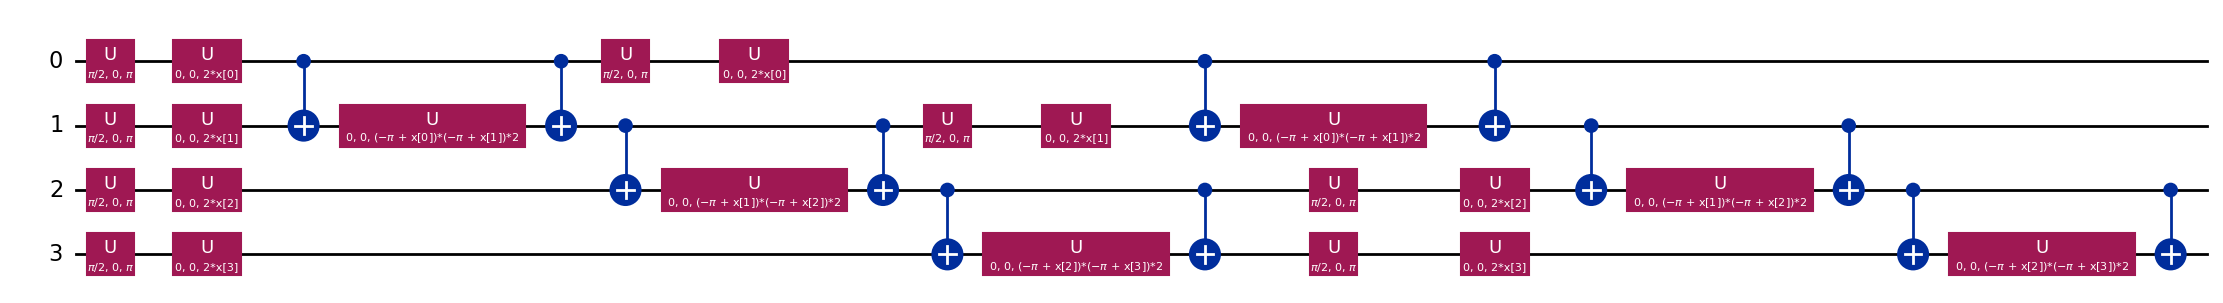

In [5]:
zz_map.decompose().draw(output="mpl", fold=80)

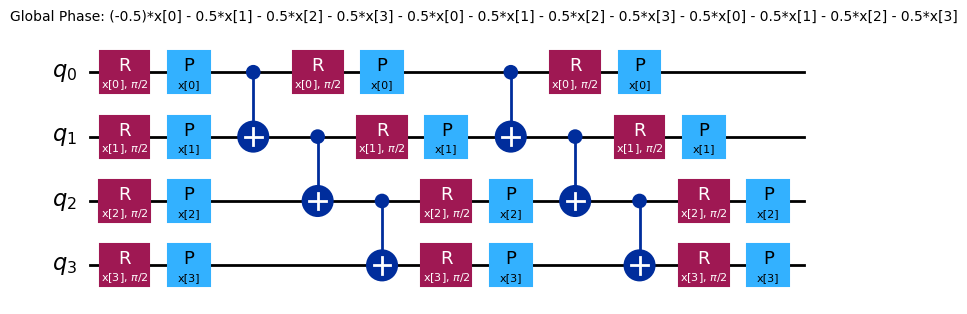

In [6]:
hea_map.decompose().draw(output="mpl", fold=80)

In [7]:
def train_and_evaluate_qsvm(feature_map, model_name, X_train, y_train, X_test, y_test):
    print("=" * 70)
    print(f"Running model: {model_name}")
    print("=" * 70)

    start_time = time.time()

    # 1. Build the ideal (noiseless) quantum kernel
    quantum_kernel = FidelityStatevectorKernel(feature_map=feature_map)

    # 2. Compute the training kernel matrix: K_train[i,j] = K(x_i, x_j)
    print("Computing training kernel matrix...")
    K_train = quantum_kernel.evaluate(x_vec=X_train)
    K_train = np.real(K_train)

    # 3. Train the SVM
    print("Training SVM...")
    svm = SVC(kernel="precomputed", C=1.0)
    svm.fit(K_train, y_train)

    # 4. Compute the test kernel matrix: K_test[i,j] = K(x_test_i, x_train_j)
    print("Computing testing kernel matrix...")
    K_test = quantum_kernel.evaluate(x_vec=X_test, y_vec=X_train)
    K_test = np.real(K_test)

    # 5. Predict
    y_pred = svm.predict(K_test)

    # 6. Evaluate
    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    elapsed_time = time.time() - start_time

    print(f"\nModel: {model_name}")
    print(f"Testing accuracy: {acc:.4f}")
    print(f"Elapsed time: {elapsed_time:.2f} seconds")
    print("\nConfusion matrix:")
    print(cm)

    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    ))

    result = {
        "model_name": model_name,
        "test_accuracy": acc,
        "elapsed_time_sec": elapsed_time,
        "kernel_train": K_train,
        "kernel_test": K_test,
        "y_pred": y_pred,
        "confusion_matrix": cm
    }

    return result

In [8]:
result_zz = train_and_evaluate_qsvm(
    feature_map=zz_map,
    model_name="QSVM with ZZFeatureMap",
    X_train=X_train_scaled,
    y_train=y_train,
    X_test=X_test_scaled,
    y_test=y_test
)

Running model: QSVM with ZZFeatureMap
Computing training kernel matrix...
Training SVM...
Computing testing kernel matrix...



Model: QSVM with ZZFeatureMap
Testing accuracy: 0.7667
Elapsed time: 0.37 seconds

Confusion matrix:
[[8 1 1]
 [0 8 2]
 [1 2 7]]

Classification report:
              precision    recall  f1-score   support

      setosa       0.89      0.80      0.84        10
  versicolor       0.73      0.80      0.76        10
   virginica       0.70      0.70      0.70        10

    accuracy                           0.77        30
   macro avg       0.77      0.77      0.77        30
weighted avg       0.77      0.77      0.77        30



In [9]:
result_hea = train_and_evaluate_qsvm(
    feature_map=hea_map,
    model_name="QSVM with Hardware Efficient Feature Map",
    X_train=X_train_scaled,
    y_train=y_train,
    X_test=X_test_scaled,
    y_test=y_test
)

Running model: QSVM with Hardware Efficient Feature Map
Computing training kernel matrix...
Training SVM...


Computing testing kernel matrix...



Model: QSVM with Hardware Efficient Feature Map
Testing accuracy: 0.9667
Elapsed time: 0.34 seconds

Confusion matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [10]:
results_df = pd.DataFrame([
    {
        "Model": result_zz["model_name"],
        "Test Accuracy": result_zz["test_accuracy"],
        "Elapsed Time (s)": result_zz["elapsed_time_sec"],
        "Circuit Depth": zz_map.decompose().depth(),
        "Number of Qubits": zz_map.num_qubits,
        "Number of Parameters": zz_map.num_parameters
    },
    {
        "Model": result_hea["model_name"],
        "Test Accuracy": result_hea["test_accuracy"],
        "Elapsed Time (s)": result_hea["elapsed_time_sec"],
        "Circuit Depth": hea_map.decompose().depth(),
        "Number of Qubits": hea_map.num_qubits,
        "Number of Parameters": hea_map.num_parameters
    }
])

display(results_df)

,Model,Test Accuracy,Elapsed Time (s),Circuit Depth,Number of Qubits,Number of Parameters
0,QSVM with ZZFeatureMap,0.766667,0.365453,19,4,4
1,QSVM with Hardware Efficient Feature Map,0.966667,0.337029,11,4,4


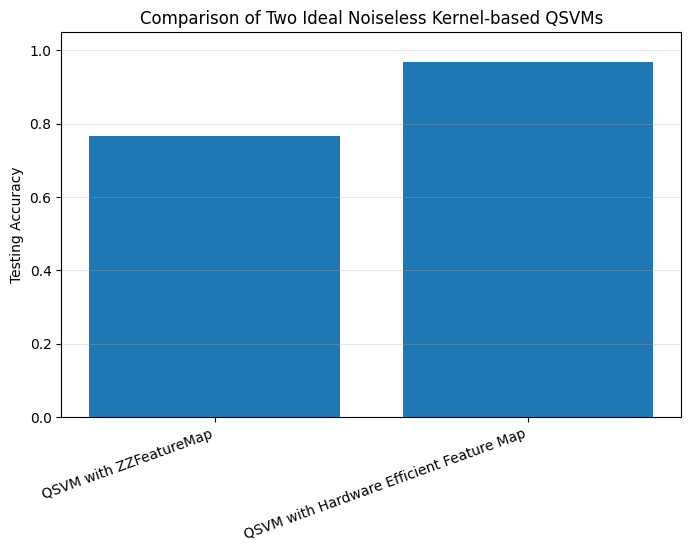

In [11]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Test Accuracy"])
plt.ylabel("Testing Accuracy")
plt.title("Comparison of Two Ideal Noiseless Kernel-based QSVMs")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.show()

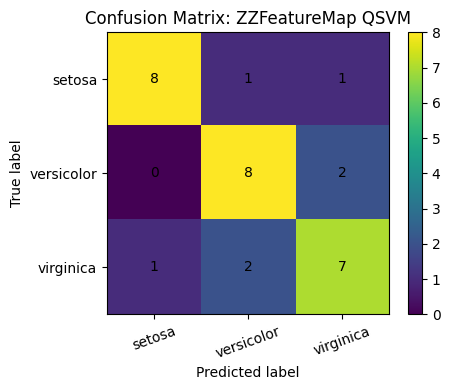

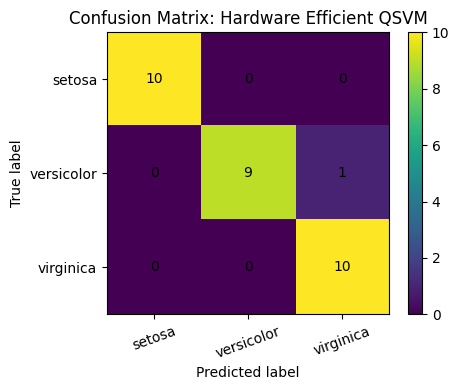

In [12]:
def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(5, 4))
    plt.imshow(cm)
    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.colorbar()

    labels = iris.target_names
    plt.xticks(np.arange(len(labels)), labels, rotation=20)
    plt.yticks(np.arange(len(labels)), labels)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, cm[i, j], ha="center", va="center")

    plt.tight_layout()
    plt.show()


plot_confusion_matrix(
    result_zz["confusion_matrix"],
    "Confusion Matrix: ZZFeatureMap QSVM"
)

plot_confusion_matrix(
    result_hea["confusion_matrix"],
    "Confusion Matrix: Hardware Efficient QSVM"
)

In [13]:
results_df.to_csv("qsvm_iris_comparison_results.csv", index=False)
print("Saved as qsvm_iris_comparison_results.csv")

Saved as qsvm_iris_comparison_results.csv


In [14]:
from google.colab import files
files.download("qsvm_iris_comparison_results.csv")

(download skipped outside Colab)


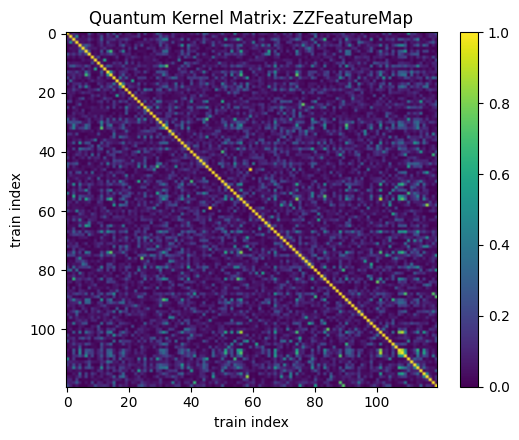

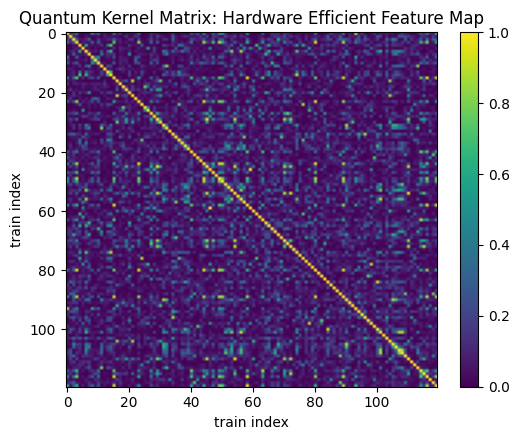

In [15]:
def plot_kernel_matrix(K, title):
    plt.figure(figsize=(5.5, 4.5))
    plt.imshow(K, aspect="auto")
    plt.colorbar()
    plt.title(title)
    plt.xlabel("train index")
    plt.ylabel("train index")
    plt.tight_layout()
    plt.show()


plot_kernel_matrix(
    result_zz["kernel_train"],
    "Quantum Kernel Matrix: ZZFeatureMap"
)

plot_kernel_matrix(
    result_hea["kernel_train"],
    "Quantum Kernel Matrix: Hardware Efficient Feature Map"
)

# Extended analysis

The original comparison above uses one 80/20 split (30 test samples), where a single misclassified sample moves accuracy by 3.3 points. The cells below check the result more carefully:

1. **Repeated cross-validation** and a **classical RBF-SVM baseline**.
2. **Feature-scaling sweep** to explain why the ZZ map underperforms (kernel concentration).
3. **Noise robustness** under a depolarizing noise model with shot sampling.

All random seeds are fixed so the numbers are reproducible.

In [16]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from qiskit.quantum_info import Statevector

X_all, y_all = iris.data, iris.target
MAPS = {"ZZ": zz_map, "HE": hea_map}

def encode(fm, Xs):
    """Statevectors |phi(x)> for every row of Xs."""
    params = sorted(fm.parameters, key=lambda p: p.index)
    return np.array([Statevector(fm.assign_parameters(dict(zip(params, x)))).data for x in Xs])

def fidelity_kernel(fm, A, B=None):
    """K[i, j] = |<phi(a_i)|phi(b_j)>|^2, computed exactly from statevectors."""
    SA = encode(fm, A)
    SB = SA if B is None else encode(fm, B)
    return np.abs(SA.conj() @ SB.T) ** 2

def qsvm_accuracy(fm, Xtr, ytr, Xte, yte, scale=2 * np.pi):
    sc = MinMaxScaler(feature_range=(0, scale)).fit(Xtr)   # fit on training data only
    A, B = sc.transform(Xtr), sc.transform(Xte)
    clf = SVC(kernel="precomputed", C=1.0).fit(fidelity_kernel(fm, A), ytr)
    return accuracy_score(yte, clf.predict(fidelity_kernel(fm, B, A)))

def rbf_accuracy(Xtr, ytr, Xte, yte):
    sc = StandardScaler().fit(Xtr)
    clf = SVC(kernel="rbf", C=1.0, gamma="scale").fit(sc.transform(Xtr), ytr)
    return accuracy_score(yte, clf.predict(sc.transform(Xte)))

# 5-fold CV repeated 10 times = 50 train/test splits
FOLDS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0).split(X_all, y_all))
print("Number of folds:", len(FOLDS))

Number of folds: 50


## 1. Repeated cross-validation and classical baseline

In [17]:
cv = {"QSVM, ZZ map": [], "QSVM, HE map": [], "Classical RBF SVM": []}
for tr, te in FOLDS:
    cv["QSVM, ZZ map"].append(qsvm_accuracy(zz_map, X_all[tr], y_all[tr], X_all[te], y_all[te]))
    cv["QSVM, HE map"].append(qsvm_accuracy(hea_map, X_all[tr], y_all[tr], X_all[te], y_all[te]))
    cv["Classical RBF SVM"].append(rbf_accuracy(X_all[tr], y_all[tr], X_all[te], y_all[te]))

single = {
    "QSVM, ZZ map": result_zz["test_accuracy"],
    "QSVM, HE map": result_hea["test_accuracy"],
    "Classical RBF SVM": rbf_accuracy(X_train, y_train, X_test, y_test),
}
cv_df = pd.DataFrame([{
    "Model": k,
    "Single split": single[k],
    "CV mean": np.mean(v),
    "CV SD": np.std(v, ddof=1),
    "Worst fold": np.min(v),
    "Best fold": np.max(v),
} for k, v in cv.items()])
display(cv_df.round(4))

,Model,Single split,CV mean,CV SD,Worst fold,Best fold
0,"QSVM, ZZ map",0.7667,0.6873,0.0670,0.5333,0.8
1,"QSVM, HE map",0.9667,0.9220,0.0407,0.8333,1.0
2,Classical RBF SVM,0.9667,0.9600,0.0337,0.8667,1.0


## 2. Feature scaling and kernel concentration

The ZZ map encodes the product (π − x_i)(π − x_j) as a phase. With features scaled to [0, 2π], that phase spans about ±20 rad, so nearby samples map to nearly unrelated states and the kernel loses structure. For two random 4-qubit states the expected fidelity is 1/16 ≈ 0.063.

Below, the scaling range [0, s] is varied. For each s we report CV accuracy and kernel statistics: the mean off-diagonal kernel value, and the mean kernel value for same-class vs. different-class pairs.

In [18]:
scales = {"π/8": np.pi / 8, "π/4": np.pi / 4, "π/2": np.pi / 2, "π": np.pi, "2π": 2 * np.pi}
off_diag = ~np.eye(len(y_all), dtype=bool)
same_cls = (y_all[:, None] == y_all[None, :]) & off_diag
diff_cls = y_all[:, None] != y_all[None, :]

rows = []
for s_name, s in scales.items():
    Xs = MinMaxScaler(feature_range=(0, s)).fit_transform(X_all)
    for m_name, fm in MAPS.items():
        K = fidelity_kernel(fm, Xs)
        accs = [qsvm_accuracy(fm, X_all[tr], y_all[tr], X_all[te], y_all[te], scale=s) for tr, te in FOLDS]
        rows.append({
            "Scale": f"[0, {s_name}]", "Map": m_name,
            "CV mean": np.mean(accs), "CV SD": np.std(accs, ddof=1),
            "Mean off-diag K": K[off_diag].mean(),
            "Same-class K": K[same_cls].mean(), "Diff-class K": K[diff_cls].mean(),
        })
scale_df = pd.DataFrame(rows)
scale_df["Same/diff ratio"] = scale_df["Same-class K"] / scale_df["Diff-class K"]
display(scale_df.round(4))

,Scale,Map,CV mean,CV SD,Mean off-diag K,Same-class K,Diff-class K,Same/diff ratio
0,"[0, π/8]",ZZ,0.9600,0.0356,0.3213,0.6582,0.1562,4.2137
1,"[0, π/8]",HE,0.9620,0.0337,0.8802,0.9781,0.8323,1.1752
2,"[0, π/4]",ZZ,0.9540,0.0349,0.1838,0.3610,0.0970,3.7213
3,"[0, π/4]",HE,0.9620,0.0323,0.6318,0.8941,0.5033,1.7766
4,"[0, π/2]",ZZ,0.9540,0.0329,0.1261,0.2316,0.0743,3.1162
5,"[0, π/2]",HE,0.9553,0.0373,0.3642,0.6614,0.2185,3.0266
6,"[0, π]",ZZ,0.8787,0.0627,0.0874,0.1242,0.0694,1.7906
7,"[0, π]",HE,0.9447,0.0407,0.1884,0.4111,0.0793,5.1808
8,"[0, 2π]",ZZ,0.6873,0.0670,0.0879,0.1157,0.0743,1.5572
9,"[0, 2π]",HE,0.9220,0.0407,0.1059,0.1856,0.0669,2.7756


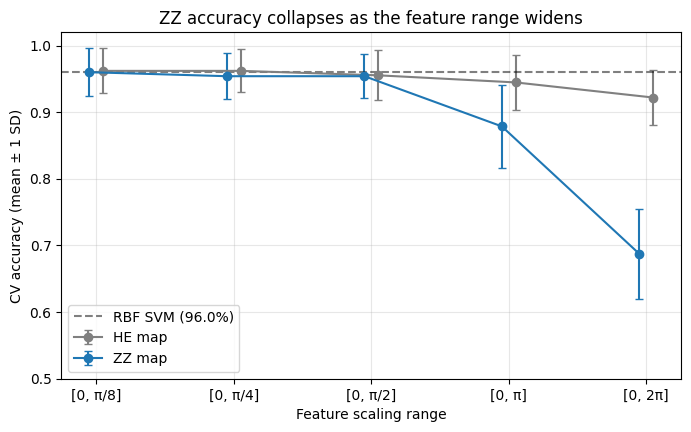

In [19]:
rbf_mean = np.mean(cv["Classical RBF SVM"])
xpos = np.arange(len(scales))
plt.figure(figsize=(8, 4.5))
for m_name, color, dx in [("HE", "gray", 0.05), ("ZZ", "tab:blue", -0.05)]:
    d = scale_df[scale_df["Map"] == m_name]
    plt.errorbar(xpos + dx, d["CV mean"], yerr=d["CV SD"], marker="o", capsize=3, color=color, label=f"{m_name} map")
plt.axhline(rbf_mean, ls="--", color="k", alpha=0.5, label=f"RBF SVM ({rbf_mean:.1%})")
plt.xticks(xpos, [f"[0, {k}]" for k in scales])
plt.xlabel("Feature scaling range")
plt.ylabel("CV accuracy (mean ± 1 SD)")
plt.title("ZZ accuracy collapses as the feature range widens")
plt.ylim(0.5, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 3. Noise robustness

Each kernel entry is estimated with a compute–uncompute circuit U(x')†U(x): the probability of measuring all zeros equals |⟨φ(x')|φ(x)⟩|² without noise. We add a depolarizing error after every gate (rate p on single-qubit gates, 10p on CX gates) and sample 1,024 shots per entry.

For speed, the noisy circuits are simulated with a small NumPy density-matrix simulator (4 qubits → 16 × 16 matrices). The next cell checks it against Qiskit Aer. Features are scaled once on the full dataset so each 150 × 150 kernel is computed only once; this step uses no labels.

In [20]:
from qiskit import transpile

def gate_program(fm):
    """Transpile the feature map to {U, CX}; return the gate list and its parameters."""
    t = transpile(fm, basis_gates=["u", "cx"], optimization_level=0)
    prog = [(ins.operation.name, [t.find_bit(b).index for b in ins.qubits], ins.operation.params) for ins in t.data]
    return prog, sorted(fm.parameters, key=lambda p: p.index)

def u_matrix(th, ph, la):
    c, s = np.cos(th / 2), np.sin(th / 2)
    return np.array([[c, -np.exp(1j * la) * s], [np.exp(1j * ph) * s, np.exp(1j * (ph + la)) * c]])

def bind_gates(prog, params, Xs):
    """For each sample, the 2x2 matrix of every U gate (None for CX)."""
    out = []
    for x in Xs:
        b = dict(zip(params, x))
        out.append([u_matrix(*[float(p.bind(b, allow_unknown_parameters=True)) if hasattr(p, "bind") else float(p) for p in ps])
                    if name == "u" else None for name, q, ps in prog])
    return out

NQ, DIM = 4, 16

def apply_1q(rho, U, q):
    B, ax = rho.shape[0], NQ - 1 - q          # Qiskit is little-endian
    r = rho.reshape((B,) + (2,) * NQ * 2)
    r = np.moveaxis(np.einsum("bij,bj...->bi...", U, np.moveaxis(r, 1 + ax, 1)), 1, 1 + ax)
    r = np.moveaxis(np.einsum("bij,bj...->bi...", U.conj(), np.moveaxis(r, 1 + NQ + ax, 1)), 1, 1 + NQ + ax)
    return r.reshape(B, DIM, DIM)

_CX = {}
def apply_cx(rho, c, t):
    if (c, t) not in _CX:
        M = np.zeros((DIM, DIM))
        for i in range(DIM):
            M[i ^ (1 << t) if (i >> c) & 1 else i, i] = 1
        _CX[(c, t)] = M
    M = _CX[(c, t)]
    return M @ rho @ M.T

def depolarize(rho, qs, lam):
    """rho -> (1 - lam) rho + lam * Tr_qs(rho) ⊗ I / 2^k on qubits qs."""
    if lam == 0:
        return rho
    B = rho.shape[0]
    r = rho.reshape((B,) + (2,) * NQ * 2)
    axes = [NQ - 1 - q for q in qs]
    tr = r
    for a in sorted(axes, reverse=True):
        tr = np.trace(tr, axis1=1 + a, axis2=1 + a + (tr.ndim - 1) // 2)
    full = np.zeros_like(r)
    for bits in np.indices((2,) * len(qs)).reshape(len(qs), -1).T:
        sl = [slice(None)] * (1 + 2 * NQ)
        for a, bv in zip(axes, bits):
            sl[1 + a] = bv
            sl[1 + NQ + a] = bv
        full[tuple(sl)] = tr / 2 ** len(qs)
    return ((1 - lam) * r + lam * full).reshape(B, DIM, DIM)

def noisy_overlap(GA, GB, prog, p1, p2, batch=2000):
    """P(0000) after U(a) then U(b)^dagger, with depolarizing noise after every gate."""
    out = np.empty(len(GA))
    for s in range(0, len(GA), batch):
        A, Bm = GA[s:s + batch], GB[s:s + batch]
        rho = np.zeros((len(A), DIM, DIM), complex)
        rho[:, 0, 0] = 1
        for g, (name, q, _) in enumerate(prog):
            if name == "u":
                rho = depolarize(apply_1q(rho, np.stack([a[g] for a in A]), q[0]), q, p1)
            else:
                rho = depolarize(apply_cx(rho, q[0], q[1]), q, p2)
        for g in reversed(range(len(prog))):
            name, q, _ = prog[g]
            if name == "u":
                rho = depolarize(apply_1q(rho, np.stack([b[g].conj().T for b in Bm]), q[0]), q, p1)
            else:
                rho = depolarize(apply_cx(rho, q[0], q[1]), q, p2)
        out[s:s + len(A)] = rho[:, 0, 0].real
    return out

for m_name, fm in MAPS.items():
    t = transpile(fm, basis_gates=["u", "cx"], optimization_level=0)
    print(f"{m_name} map: depth {t.depth()}, gates {dict(t.count_ops())}")

ZZ map: depth 19, gates {'u': 22, 'cx': 12}
HE map: depth 11, gates {'u': 24, 'cx': 6}


In [21]:
# Sanity checks: (1) noiseless result equals the exact statevector kernel,
#                (2) noisy result equals Qiskit Aer's density-matrix simulator.
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

Xs = MinMaxScaler(feature_range=(0, np.pi / 2)).fit_transform(X_all)
p = 0.01
nm = NoiseModel()
nm.add_all_qubit_quantum_error(depolarizing_error(p, 1), ["u"])
nm.add_all_qubit_quantum_error(depolarizing_error(10 * p, 2), ["cx"])
aer = AerSimulator(method="density_matrix", noise_model=nm)

for m_name, fm in MAPS.items():
    prog, params = gate_program(fm)
    G = bind_gates(prog, params, Xs)
    K = fidelity_kernel(fm, Xs)
    mine0 = noisy_overlap([G[0], G[1]], [G[1], G[2]], prog, 0, 0)
    mine = noisy_overlap([G[0], G[1]], [G[1], G[2]], prog, p, 10 * p)
    t = transpile(fm, basis_gates=["u", "cx"], optimization_level=0)
    for (a, b), m0, m in zip([(0, 1), (1, 2)], mine0, mine):
        qc = t.assign_parameters(dict(zip(params, Xs[a]))).compose(t.assign_parameters(dict(zip(params, Xs[b]))).inverse())
        qc.save_probabilities()
        p_aer = aer.run(qc).result().data()["probabilities"][0]
        print(f"{m_name} ({a},{b}): exact {K[a, b]:.6f} | sim p=0 {m0:.6f} | sim p={p} {m:.6f} | Aer {p_aer:.6f}")

ZZ (0,1): exact 0.031252 | sim p=0 0.031252 | sim p=0.01 0.060428 | Aer 0.060428
ZZ (1,2): exact 0.699025 | sim p=0 0.699025 | sim p=0.01 0.129862 | Aer 0.129862
HE (0,1): exact 0.797500 | sim p=0 0.797500 | sim p=0.01 0.262913 | Aer 0.262913


HE (1,2): exact 0.962037 | sim p=0 0.962037 | sim p=0.01 0.305821 | Aer 0.305821


In [22]:
SHOTS = 1024
NOISE_P = [0, 0.001, 0.002, 0.005, 0.01]     # single-qubit rate; CX rate = 10 * p
rng = np.random.default_rng(7)

def cv_on_kernel(K):
    accs = []
    for tr, te in FOLDS:
        clf = SVC(kernel="precomputed", C=1.0).fit(K[np.ix_(tr, tr)], y_all[tr])
        accs.append(accuracy_score(y_all[te], clf.predict(K[np.ix_(te, tr)])))
    return np.array(accs)

I, J = np.triu_indices(len(y_all), 0)
noise_rows, fold_acc = [], {}
for s_name, s in [("π/2", np.pi / 2), ("2π", 2 * np.pi)]:
    Xs = MinMaxScaler(feature_range=(0, s)).fit_transform(X_all)
    for m_name, fm in MAPS.items():
        prog, params = gate_program(fm)
        G = bind_gates(prog, params, Xs)
        for p in NOISE_P:
            f = noisy_overlap([G[i] for i in I], [G[j] for j in J], prog, p, 10 * p)
            f = rng.binomial(SHOTS, np.clip(f, 0, 1)) / SHOTS      # shot noise
            K = np.zeros((len(y_all), len(y_all)))
            K[I, J] = f
            K[J, I] = f
            accs = cv_on_kernel(K)
            fold_acc[(s_name, m_name, p)] = accs
            noise_rows.append({"Scale": f"[0, {s_name}]", "Map": m_name, "CX error": f"{10 * p:.0%}",
                               "CV mean": accs.mean(), "CV SD": accs.std(ddof=1),
                               "K(x, x) mean": np.diag(K).mean()})
        print(f"done: [0, {s_name}] {m_name}")
noise_df = pd.DataFrame(noise_rows)
display(noise_df.round(4))

done: [0, π/2] ZZ


done: [0, π/2] HE


done: [0, 2π] ZZ


done: [0, 2π] HE


,Scale,Map,CX error,CV mean,CV SD,"K(x, x) mean"
0,"[0, π/2]",ZZ,0%,0.9527,0.0381,1.0000
1,"[0, π/2]",ZZ,1%,0.9540,0.0362,0.8037
2,"[0, π/2]",ZZ,2%,0.9507,0.0358,0.6511
3,"[0, π/2]",ZZ,5%,0.9460,0.0409,0.3601
4,"[0, π/2]",ZZ,10%,0.9127,0.0490,0.1603
5,"[0, π/2]",HE,0%,0.9560,0.0365,1.0000
6,"[0, π/2]",HE,1%,0.9560,0.0372,0.8807
7,"[0, π/2]",HE,2%,0.9533,0.0381,0.7744
8,"[0, π/2]",HE,5%,0.9573,0.0357,0.5366
9,"[0, π/2]",HE,10%,0.9593,0.0358,0.3014


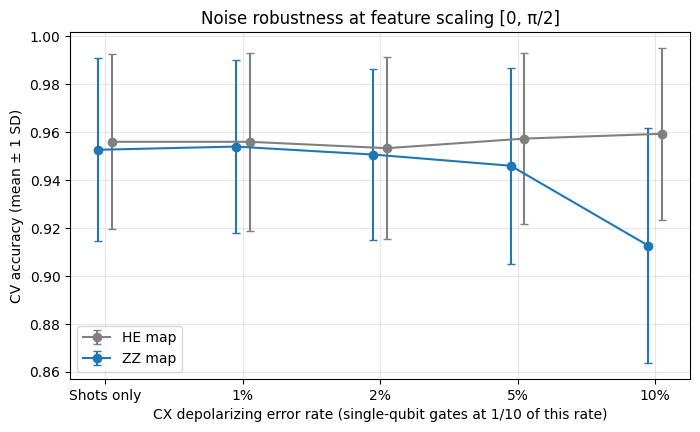

HE - ZZ at 10% CX error: mean +0.0467, HE better in 38 folds, tie in 8, worse in 4


In [23]:
d = noise_df[noise_df["Scale"] == "[0, π/2]"]
labels = ["Shots only"] + [f"{10 * p:.0%}" for p in NOISE_P[1:]]
xpos = np.arange(len(NOISE_P))
plt.figure(figsize=(8, 4.5))
for m_name, color, dx in [("HE", "gray", 0.05), ("ZZ", "tab:blue", -0.05)]:
    dd = d[d["Map"] == m_name]
    plt.errorbar(xpos + dx, dd["CV mean"], yerr=dd["CV SD"], marker="o", capsize=3, color=color, label=f"{m_name} map")
plt.xticks(xpos, labels)
plt.xlabel("CX depolarizing error rate (single-qubit gates at 1/10 of this rate)")
plt.ylabel("CV accuracy (mean ± 1 SD)")
plt.title("Noise robustness at feature scaling [0, π/2]")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Paired comparison on the same folds at the highest noise level
diff = fold_acc[("π/2", "HE", 0.01)] - fold_acc[("π/2", "ZZ", 0.01)]
print(f"HE - ZZ at 10% CX error: mean {diff.mean():+.4f}, "
      f"HE better in {(diff > 0).sum()} folds, tie in {(diff == 0).sum()}, worse in {(diff < 0).sum()}")

## Conclusion

- On one 30-sample split, HE beat ZZ 96.7% to 76.7%. Under repeated 5-fold CV, HE averages 92.2% and ZZ 68.7%; a classical RBF SVM reaches 96.0%.
- The ZZ deficit comes from feature scaling. At [0, 2π] the ZZ kernel is concentrated near 1/16; at [0, π/2] or less, both maps reach 95–96%, on par with the classical baseline.
- HE uses half the CX gates (6 vs. 12 per encoding) and holds its accuracy under heavy depolarizing noise, while ZZ loses about 4–5 points at 10% CX error.
- Limitations: Iris is small and nearly linearly separable; all results are simulated; the noise model covers gate depolarization and shot noise only; C = 1 was not tuned.